In [13]:
import numpy as np, scipy, pandas, matplotlib.pyplot as plt
print("all good")

all good


In [14]:
def hold_golden(p, a=0, b=0):
    q = 1-p
    if a == 3 and b == 3: #40-40
        return p
    if a == 4: #server won
        return 1
    if b == 4: #receiver won
        return 0
    return p * hold_golden(p, a+1, b) + q * hold_golden(p, a, b+1)


In [15]:
p = 0.5
print(hold_golden(p, 2, 3))
print(hold_golden(p, 3, 2))
print(hold_golden(p, 3, 1))
print(hold_golden(p, 0, 0))

0.25
0.75
0.875
0.5


In [16]:
def hold_deuce(p, a=0, b=0):
    q = 1-p
    if a == 3 and b == 3:
        return p**2 / (p**2 + q**2) #win from deuce
    if a == 4: #server won
        return 1
    if b == 4: #receiver won
        return 0
    return p * hold_deuce(p, a+1, b) + q * hold_deuce(p, a, b+1)

In [17]:
p = 0.6
print(hold_deuce(p))
print(hold_golden(p))

0.7357292307692308
0.710208


In [18]:
def hold_star(p, a=0, b=0):
    q = 1-p
    if a == 3 and b ==3: #win from first deuce
        d3 = p
        d2 = p**2 + 2*p*q*d3
        d1 = p**2 + 2*p*q*d2
        return d1
    if a == 4: #server won
        return 1
    if b == 4: #receiver won
        return 0
    return p * hold_star(p, a+1, b) + q * hold_star(p, a, b+1)

In [19]:
p = 0.6
print(hold_deuce(p))
print(hold_golden(p))
print(hold_star(p))

0.7357292307692308
0.710208
0.7298491391999999


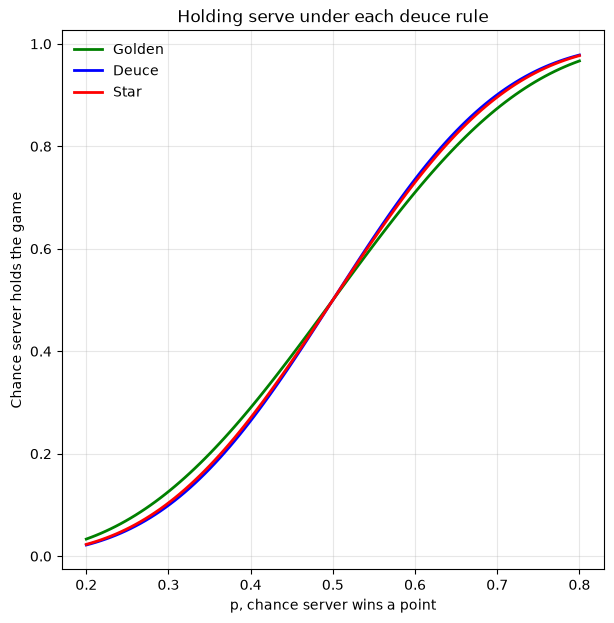

In [20]:
ps = np.linspace(0.2, 0.8, 101) #probability space

golden = [hold_golden(p) for p in ps]
deuce = [hold_deuce(p) for p in ps]
star = [hold_star(p) for p in ps]

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(ps, golden, color="green", lw=2, label="Golden")
ax.plot(ps, deuce, color="blue", lw=2, label="Deuce")
ax.plot(ps, star, color="red", lw=2, label="Star")
ax.set_xlabel("p, chance server wins a point")
ax.set_ylabel("Chance server holds the game")
ax.set_title("Holding serve under each deuce rule")
ax.legend(frameon=False)
ax.grid(alpha=0.3)

In [21]:
def temp_set_prob(h_a, h_b, ga=0, gb=0, server = "A"): #where ga and gb are games won by a and b respectively
    if (ga>=6 and ga-gb>=2) or ga==7: #A wins the set
        return 1
    if (gb>=6 and gb-ga>=2) or gb==7: #B wins the set
        return 0
    if ga==6 and gb==6:
        return 0.5 #tiebreak placeholder

    if server == "A":
        x = h_a
        next_server = "B"
    else:
        x = 1-h_b
        next_server = "A"
    return x * temp_set_prob(h_a, h_b, ga+1, gb, next_server) + (1-x) * temp_set_prob(h_a, h_b, ga, gb+1, next_server)

In [22]:
h_a = hold_star(0.62)
h_b = hold_star(0.58)
print(h_a, h_b)
print(temp_set_prob(h_a, h_b, server="A")) 
print(temp_set_prob(h_a, h_b, server="B")) 
print(temp_set_prob(0.7, 0.7))

0.7696531366363824 0.6873466366545624
0.6221187804999047
0.6221187804999047
0.5


In [23]:
def tiebreak_prob(p_a, p_b, a=0, b=0, first="A"):
    if a>=7 and a-b>=2:
        return 1
    if b>=7 and b-a>=2:
        return 0
    if a==b and a>=6:
        w = p_a * (1-p_b)
        l = (1-p_a) * p_b
        return w/(w+l)

    n = a+b
    if ((n+1) //2 ) % 2 == 0:
        server = first
    else:
        server = "B" if first=="A" else "A"

    if server == "A":
        x = p_a
    else:
        x = 1-p_b
    return x * tiebreak_prob(p_a, p_b, a+1, b, first) + (1-x) * tiebreak_prob(p_a, p_b, a, b+1, first)

In [24]:
def set_prob(p_a, p_b, hold=hold_star, ga=0, gb=0, server = "A"): #where ga and gb are games won by a and b respectively
    h_a = hold(p_a)
    h_b = hold(p_b)

    if (ga>=6 and ga-gb>=2) or ga==7: #A wins the set
        return 1
    if (gb>=6 and gb-ga>=2) or gb==7: #B wins the set
        return 0
    if ga==6 and gb==6:
        return tiebreak_prob(p_a, p_b, first=server)

    if server == "A":
        x = h_a
        next_server = "B"
    else:
        x = 1-h_b
        next_server = "A"
    return x * set_prob(p_a, p_b, hold, ga+1, gb, next_server) + (1-x) * set_prob(p_a, p_b, hold, ga, gb+1, next_server)

In [25]:
p_a, p_b = 0.62, 0.58

print(tiebreak_prob(0.6, 0.6))
print(tiebreak_prob(p_a, p_b))
print(tiebreak_prob(p_a, p_b, first="B"))
print(set_prob(p_a, p_b))

0.5
0.5645021922472874
0.5645021922472873
0.632588187725585


In [26]:
def match_prob(p_a, p_b, hold=hold_star):
    s = set_prob(p_a, p_b, hold)
    return s**2 + 2*s*(1-s)*s

In [27]:
p_a, p_b = 0.62, 0.58

print("point (avg):", (p_a + (1 - p_b)) / 2)
print("game  (avg):", (hold_star(p_a) + (1 - hold_star(p_b))) / 2)
print("set:", set_prob(p_a, p_b))
print("match:", match_prob(p_a, p_b))

point (avg): 0.52
game  (avg): 0.54115324999091
set: 0.632588187725585
match: 0.6942205796796874
